# Tedarik süresinde kaç birim stok hazır olmalı?

Tek ürünün tedarik süresindeki talebi değişken. Fazla stok birim başına 3, eksik stok 9 kayıp puanı yaratıyor. Ortalama talep kolay hesaplanıyor, ama eksik ve fazla stok sonuçları eşit ağırlıkta değil.

Karar: Hangi stok miktarı maliyet dengesine aday? Tam karşılama hedefi farklı bir miktar gerektiriyor mu?

Veriler sentetiktir. Her senaryo sabit tohumla aynı veriyi yeniden oluşturur. CSV dosyaları örnek çıktıdır. Bir CSV’yi değiştirmen bu defterin verisini otomatik değiştirmez.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import expit
import matplotlib.pyplot as plt

BLUE, ORANGE, GREEN, GRAY = '#2457ad', '#ac452c', '#197254', '#64748b'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'axes.axisbelow': True, 'grid.alpha': .19})

def table(frame, title):
    return dict(title=title, columns=frame.columns.tolist(),
                rows=frame.astype(object).where(frame.notna(), None).values.tolist())

def stock(scenario='default'):
    rng=np.random.default_rng(72106)
    history=rng.poisson(80,180)+rng.binomial(1,.22,180)*rng.poisson(34,180)
    actual=rng.poisson(80,60)+rng.binomial(1,.22,60)*rng.poisson(34,60)
    if scenario=='surge':
        actual=actual+25
    short,extra=9,3
    q=short/(short+extra)
    stock=int(np.quantile(history,q,method='inverted_cdf'))
    mean=int(np.round(np.mean(history)))
    high=int(np.quantile(history,.95,method='inverted_cdf'))
    rows=[]
    def measure(demand,available):
        shortage=np.maximum(demand-available,0)
        excess=np.maximum(available-demand,0)
        return [np.mean(demand<=available),1-shortage.sum()/demand.sum(),np.mean(short*shortage+extra*excess)]
    for label,s in [('Yuvarlanmış ortalama',mean),('Maliyet dengesi P75',stock),('Yüksek hizmet P95',high)]:
        rows.append([label,s,*measure(history,s),*measure(actual,s)])
    detail=pd.DataFrame(rows,columns=['Politika','Stok · adet','Geçmiş tam karşılama','Geçmiş birim doluluk','Geçmiş kayıp',
                                    'Final tam karşılama','Final birim doluluk','Final kayıp'])
    grid=np.arange(55,165)
    loss=np.array([measure(history,s)[2] for s in grid])
    assert np.isclose(measure(history,stock)[2],loss.min())
    fig,ax=plt.subplots(figsize=(8.7,4.3),layout='constrained')
    for x,color,label in [(history,BLUE,'Geçmiş'),(actual,ORANGE,'Final')]:
        xs=np.sort(x)
        ax.step(xs,np.arange(1,len(xs)+1)/len(xs),where='post',color=color,label=label)
    ax.axvline(stock,color=GREEN,ls='--',label=f'Donmuş P75: {stock} adet')
    ax.set(xlabel='Tedarik süresi boyunca talep · adet',ylabel='Talebin bu değeri aşmama payı',title='Aynı stok düzeyi, değişen talep')
    ax.legend()
    fig2,ax2=plt.subplots(figsize=(8.7,3.7),layout='constrained')
    ax2.plot(grid,loss,color=BLUE,label='Geçmiş kayıp')
    ax2.plot(grid,[measure(actual,s)[2] for s in grid],color=ORANGE,label='Final kayıp, yalnız değerlendirme')
    ax2.axvline(stock,color=GREEN,ls='--',label='Geçmişten seçilen miktar')
    ax2.set(xlabel='Elde hazır stok · adet',ylabel='Döngü başına kayıp puanı',title='Eksik ve fazla stok maliyetinin dengesi')
    ax2.legend(fontsize=8)
    m=rows[1]
    raw=pd.DataFrame({'Tedarik döngüsü':np.arange(1,241),'Kesit':np.repeat(['Geçmiş','Final'],[180,60]),'Talep · adet':np.r_[history,actual]})
    return dict(metrics={'Eksik / fazla puan':'9 / 3','Geçmiş maliyet kantili':'P75','Donmuş stok · adet':stock,
                         'Final tam karşılama · %':100*m[5],'Final birim doluluk · %':100*m[6],'Final ortalama kayıp':m[7]},
        tables=[table(detail,'Üç önceden belirlenmiş stok politikasının kıyası')],
        figures=[('Yatay eksende stok miktarını bul. Eğri yüksekliği, tüm döngü talebinin karşılanma payını verir.',fig),
                 ('Politika geçmişte seçilir. Final kayıp eğrisi sonucu açıklamak içindir, aynı finalden yeni başarı seçilmez.',fig2)],
        frames={'tedarik_dongusu':raw,'stok_politikalari':detail},
        steps=['Bir satır tedarik süresince oluşan talebi gösterir. Fazla birime 3, eksik birime 9 kayıp puanı ata.',
               'Tek dönem doğrusal kayıp modelinde hedef kantil 9/(9+3)=0,75. İlk 180 döngünün ampirik P75 değerini dondur.',
               'Son 60 döngüde tam karşılama payı, karşılanan birim payı ve kaybı ayrı raporla. Aynı stok değişen dağılımda farklı sonuç verir.'],
        decision='Geçmişten seçilmiş miktar ani talep artışında güvenilir hizmet sağlamıyor. Satış ve tedarik ekipleriyle artışın kaynağını doğrula, yeni dönem için önceden belirlenen yeniden hesaplama sürecini başlat.' if scenario=='surge' else 'Maliyet ve hizmet hedefleri farklı. P75 maliyet puanına, P95 tam karşılama hedeflerine aday olabilir. Fazla stok riskini ve kapasite kısıtını kararla birlikte değerlendir.',
        limit='Tek dönem, sabit eksik/fazla puanı, bir ürün ve bağımsız döngüler varsayılır. Teslim süresi belirsizliği talep penceresine dahil edilmelidir. Bu çözüm çok ürünlü sipariş politikası veya sürekli stok optimizasyonu değildir.',
        diagnostics={'stock':stock,'fractile':q,'history_n':180,'test_n':60,'test_fill':m[6],'test_cycle':m[5],'test_loss':m[7]},
        focus=[['Geçmiş','180 döngü','Miktarı burada seç'],['Maliyet dengesi',f'P75 → {stock} adet','9 eksik / 3 fazla puan'],['Final',f'%{m[5]*100:.1f} tam karşılama','60 ayrı döngüde değerlendir']])


def print_result(result):
    for name, value in result['metrics'].items():
        print(f"{name}: {value}")
    print()
    for t in result['tables']:
        print(t['title'])
        print(pd.DataFrame(t['rows'], columns=t['columns']).to_string(index=False))
        print()
    print('Karar:', result['decision'])
    print('Koşullar:', result['limit'])


## Talep yapısı benzer

Eksik stok 9, fazla stok 3 kayıp puanı. Tek dönem maliyet dengesinin hedef kantili yüzde kaç?


Eksik / fazla puan: 9 / 3
Geçmiş maliyet kantili: P75
Donmuş stok · adet: 94
Final tam karşılama · %: 73.33333333333333
Final birim doluluk · %: 95.71565802113352
Final ortalama kayıp: 66.35

Üç önceden belirlenmiş stok politikasının kıyası
            Politika  Stok · adet  Geçmiş tam karşılama  Geçmiş birim doluluk  Geçmiş kayıp  Final tam karşılama  Final birim doluluk  Final kayıp
Yuvarlanmış ortalama           88              0.655556              0.924489     80.216667             0.666667             0.936215        70.15
 Maliyet dengesi P75           94              0.755556              0.945060     76.550000             0.733333             0.957157        66.35
   Yüksek hizmet P95          121              0.950000              0.995949    103.950000             0.983333             0.999616       103.15

Karar: Maliyet ve hizmet hedefleri farklı. P75 maliyet puanına, P95 tam karşılama hedeflerine aday olabilir. Fazla stok riskini ve kapasite kısıtını kararla birlikte değe

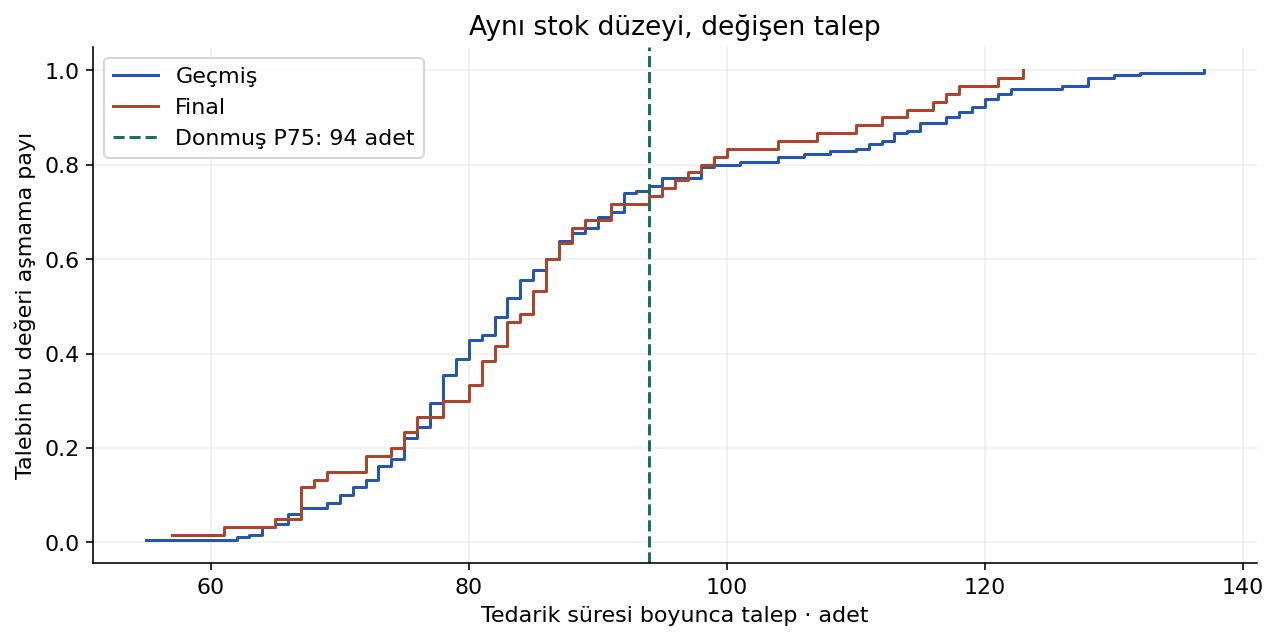

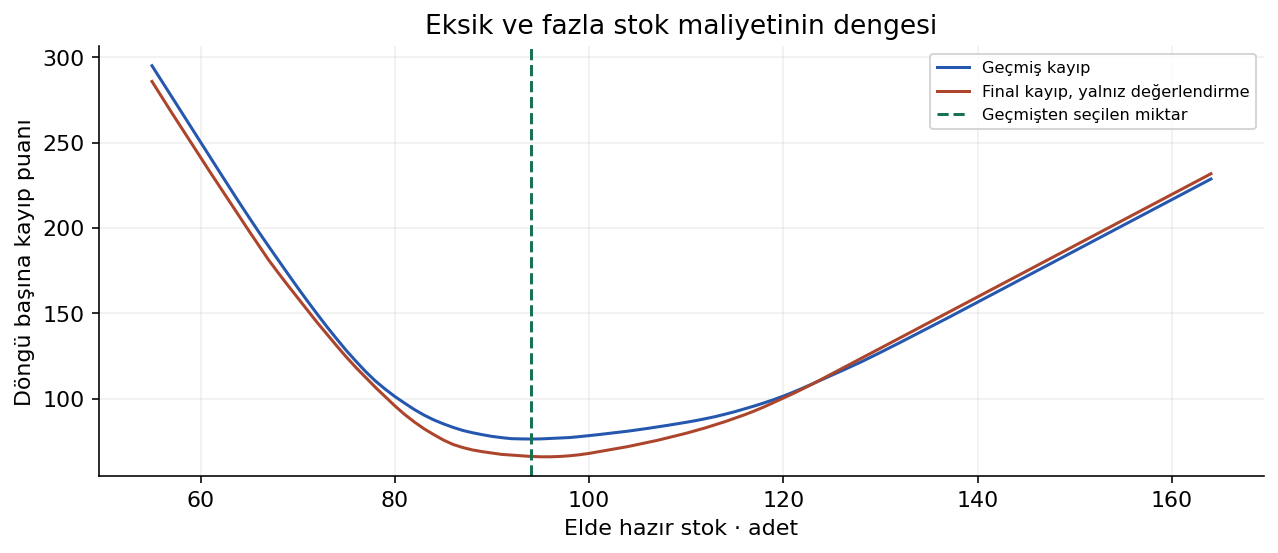

In [2]:
result = stock('default')
print_result(result)
plt.show()


## Sonraki dönemde talep +25 adet

Eksik stok 9, fazla stok 3 kayıp puanı. Tek dönem maliyet dengesinin hedef kantili yüzde kaç?


Eksik / fazla puan: 9 / 3
Geçmiş maliyet kantili: P75
Donmuş stok · adet: 94
Final tam karşılama · %: 15.0
Final birim doluluk · %: 83.6241610738255
Final ortalama kayıp: 166.35

Üç önceden belirlenmiş stok politikasının kıyası
            Politika  Stok · adet  Geçmiş tam karşılama  Geçmiş birim doluluk  Geçmiş kayıp  Final tam karşılama  Final birim doluluk  Final kayıp
Yuvarlanmış ortalama           88              0.655556              0.924489     80.216667             0.033333             0.786279       215.35
 Maliyet dengesi P75           94              0.755556              0.945060     76.550000             0.150000             0.836242       166.35
   Yüksek hizmet P95          121              0.950000              0.995949    103.950000             0.766667             0.971365        66.15

Karar: Geçmişten seçilmiş miktar ani talep artışında güvenilir hizmet sağlamıyor. Satış ve tedarik ekipleriyle artışın kaynağını doğrula, yeni dönem için önceden belirlenen yeniden he

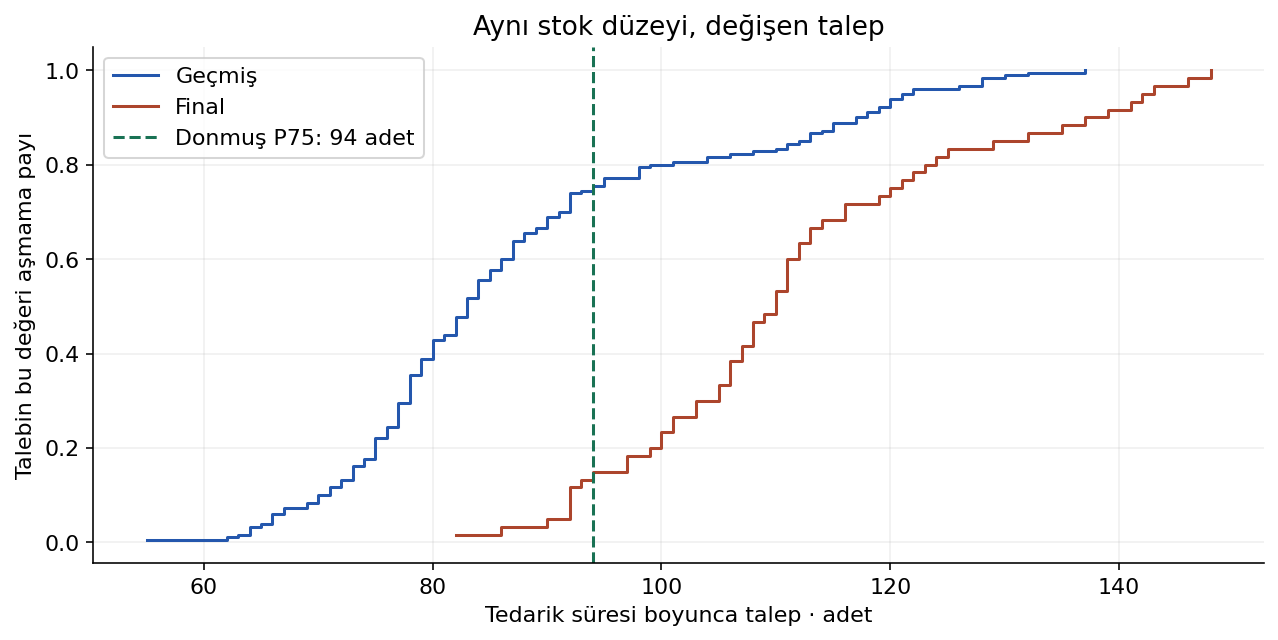

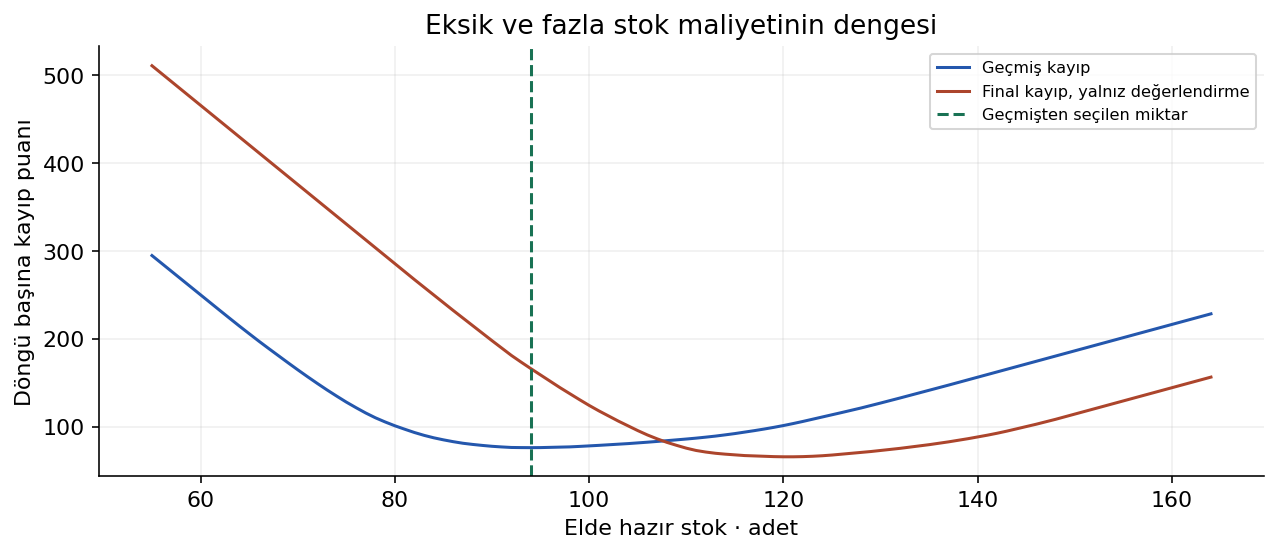

In [3]:
result = stock('surge')
print_result(result)
plt.show()


## Karar notu

P75 stok aynı kalırken talep artışı tam karşılama ve birim doluluğu nasıl değiştiriyor? Bir sonraki stok kararında hangi veri ve maliyetleri tekrar doğrularsın?

- Kantili 9/(9+3) olarak hesapla.
- Tam karşılama ile doluluğun paydalarını ayrı belirt.
- Final artışı karşısında eski stok miktarının yeni hedefi garanti etmediğini göster.